In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import generate_behavdf as gm
# from preproc_funcs import *
# from generate_plots import *
# from helpers import *
# from preproc_funcs import *
from scipy import stats
import plotly.graph_objects as go
from statsmodels.stats.anova import AnovaRM
import pingouin as pg

pd.set_option("display.max.columns", None)
pd.set_option("display.precision", 4)

msize = 10
axes_fontsize = 14
title_fontsize = 18
%load_ext autoreload
%autoreload 2

Creating a new dataframe...
We have 7 subjects so far: [1, 2, 5, 7, 8, 11, 12]



In [2]:
df = gm.master_df
oriArrayCols = [col for col in df.columns if col.startswith('oriArray_')]
df['oriSteps'] = df[oriArrayCols].notna().sum(axis=1)
df['abserrorOri'] = np.abs(df['errorOri'])
df['stimPF_label'] = df['stimPF'].apply(lambda x: 'outPF' if x == 0 else 'inPF')
df['TMScond_label'] = df['TMScond'].apply(lambda x: 'No TMS' if x == 1 else 'Early TMS' if x == 2 else 'Middle TMS')

/var/folders/cf/d9j3_ppd5wb4bn9y_fgj3nb800010l/T/ipykernel_80378/2891304939.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['oriSteps'] = df[oriArrayCols].notna().sum(axis=1)
/var/folders/cf/d9j3_ppd5wb4bn9y_fgj3nb800010l/T/ipykernel_80378/2891304939.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['abserrorOri'] = np.abs(df['errorOri'])
/var/folders/cf/d9j3_ppd5wb4bn9y_fgj3nb800010l/T/ipykernel_80378/2891304939.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.i

In [3]:
df_check = df[(df['subjID'] == 7) & (df['day'] == 2)]
df_check['block'].unique()

array([ 1,  2,  3,  4,  5,  6,  9, 10, 11])

In [3]:
df.head()

,subjID,day,block,TMScond,stimPF,targOriCategory,targOriActual,stimSize,targX,targY,rho,polang,initDuration,sampleDuration,delay1Duration,delay2Duration,respDuration,feedbackDuration,itiDuration,trialDuration,initOri,oriArray_1,oriArray_2,oriArray_3,oriArray_4,oriArray_5,oriArray_6,oriArray_7,oriArray_8,oriArray_9,oriArray_10,oriArray_11,oriArray_12,oriArray_13,oriArray_14,oriArray_15,oriArray_16,oriArray_17,oriArray_18,oriArray_19,oriArray_20,oriArray_21,oriArray_22,oriArray_23,oriArray_24,oriArray_25,oriArray_26,oriArray_27,oriArray_28,oriArray_29,oriArray_30,oriArray_31,oriArray_32,oriArray_33,oriArray_34,oriArray_35,oriArray_36,oriArray_37,oriArray_38,oriArray_39,oriArray_40,oriArray_41,oriArray_42,oriArray_43,oriArray_44,oriArray_45,oriArray_46,oriArray_47,oriArray_48,oriArray_49,oriArray_50,oriArray_51,oriArray_52,oriArray_53,oriArray_54,oriArray_55,oriArray_56,oriArray_57,oriArray_58,oriArray_59,oriArray_60,oriArray_61,oriArray_62,oriArray_63,oriArray_64,oriArray_65,oriArray_66,oriArray_67,oriArray_68,oriArray_69,oriArray_70,oriArray_71,oriArray_72,oriArray_73,oriArray_74,oriArray_75,oriArray_76,oriArray_77,oriArray_78,oriArray_79,oriArray_80,oriArray_81,oriArray_82,oriArray_83,oriArray_84,oriArray_85,oriArray_86,oriArray_87,oriArray_88,oriArray_89,oriArray_90,oriArray_91,oriArray_92,oriArray_93,oriArray_94,oriArray_95,oriArray_96,oriArray_97,oriArray_98,oriArray_99,oriArray_100,oriArray_101,oriArray_102,oriArray_103,oriArray_104,oriArray_105,oriArray_106,oriArray_107,oriArray_108,oriArray_109,oriArray_110,oriArray_111,oriArray_112,oriArray_113,oriArray_114,oriArray_115,oriArray_116,oriArray_117,oriArray_118,oriArray_119,oriArray_120,finalOri,RT,errorOri,oriArray_121,oriSteps,abserrorOri,stimPF_label,TMScond_label
0,1,1,1,3,1,150,150.4502,182,1264.895,691.8237,340.6045,26.4712,1.0002,0.2502,2.0002,2.0003,1.3968,1.0005,1.5002,9.1502,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,127.0883,128.0883,129.0883,130.0883,131.0883,133.0883,133.0883,135.0883,136.0883,136.0883,137.0883,139.0883,140.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,141.0883,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,141.0883,1.3240,9.3619,NaN,52,9.3619,inPF,Middle TMS
1,1,1,1,3,1,150,141.0927,182,1264.895,691.8237,340.6045,26.4712,1.0003,0.2502,2.0002,2.0002,1.2362,1.0002,1.5003,8.9890,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,171.0400,169.0400,166.0400,163.0400,161.0400,158.0400,155.0400,152.0400,148.0400,145.0400,141.0400,139.0400,138.0400,136.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,135.0400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,135.0400,1.2067,6.0527,NaN,49,6.0527,inPF,Middle TMS
2,1,1,1,3,0,30,39.4616,182,655.105,691.8237,340.6045,153.5288,1.0003,0.2502,2.0002,2.0002,1.1356,1.0002,2.5002,9.8879,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,80.2055,79.2055,77.2055,73.2055,70.2055,67.2055,63.2055,60.2055,57.2055,54.2055,50.2055,46.2055,45.2055,44.2055,44.2055,44.2055,44.2055,44.2055,44.2055,44.2055,44.2055,44.205

Subject 1 has 12 trials with abserrorOri > 3 std devs from the mean
Subject 2 has 5 trials with abserrorOri > 3 std devs from the mean
Subject 5 has 6 trials with abserrorOri > 3 std devs from the mean
Subject 7 has 2 trials with abserrorOri > 3 std devs from the mean
Subject 8 has 16 trials with abserrorOri > 3 std devs from the mean
Subject 11 has 9 trials with abserrorOri > 3 std devs from the mean
Subject 12 has 4 trials with abserrorOri > 3 std devs from the mean


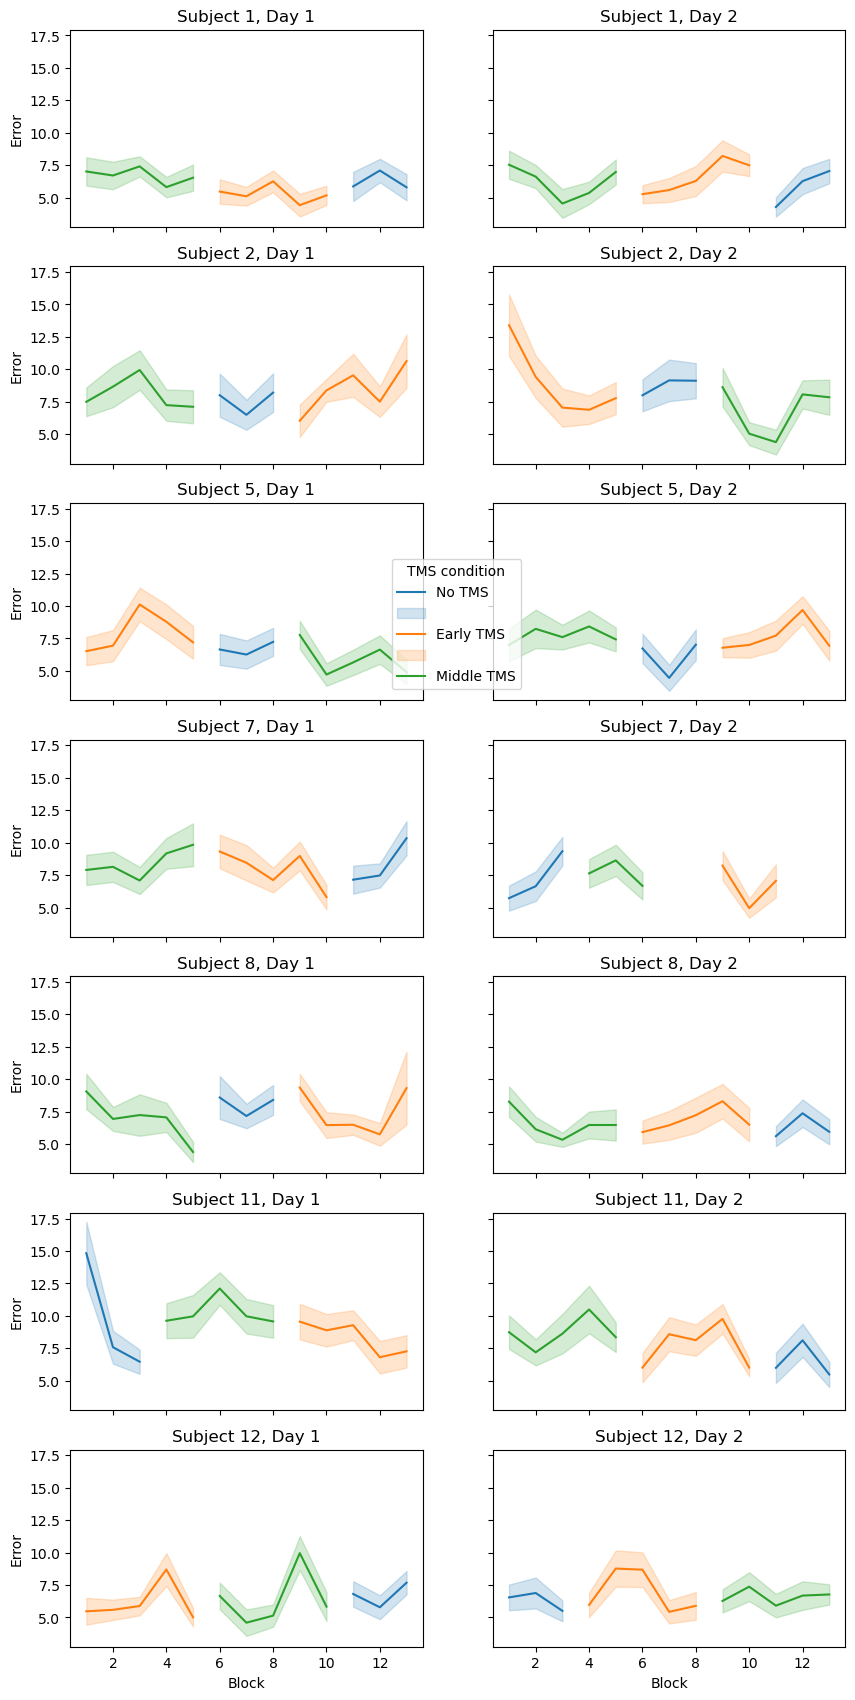

In [4]:
unique_subs = df['subjID'].unique()
f, axs = plt.subplots(len(unique_subs), 2, figsize=(10, 3*len(unique_subs)), sharex=True, sharey=True)

metric_to_plot = 'abserrorOri'
# metric_to_plot = 'RT'
for i, sub in enumerate(unique_subs):
    subdf = df[df['subjID'] == sub]
    # Eliminate rows where abserrorOri is greater than 3 std devs from the mean
    elimTrials = np.abs(subdf['abserrorOri'] - subdf['abserrorOri'].mean()) > 3*subdf['abserrorOri'].std()
    print(f'Subject {sub} has {elimTrials.sum()} trials with abserrorOri > 3 std devs from the mean')
    subdf = subdf[~elimTrials]

    # # Plot distributions for RT and error
    nunique_days = subdf['day'].nunique()
    # nbins = 50
    # daydf = subdf[subdf['day']==1]

    # axs[i, 0].hist(daydf[metric_to_plot], bins=nbins, alpha=0.5, color='blue')
    # axs[i, 0].set_title(f'Subject {sub}, Day 1')
    

    # if nunique_days == 2:
    #     daydf = subdf[subdf['day']==2]
    #     axs[i, 1].hist(daydf[metric_to_plot], bins=nbins, alpha=0.5, color='blue')
    #     axs[i, 1].set_title(f'Subject {sub}, Day 2')

    if nunique_days == 1:
        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf, ax=axs[i, 0], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 0].set_title(f'Subject {sub}, Day 1')
        axs[i, 0].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 0].set_ylabel('Error')
        else:
            axs[i, 0].set_ylabel('RT')
        # axs[i, 0].legend(title='Stimulus position')
    else:
        
        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf[subdf['day']==1], ax=axs[i, 0], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 0].set_title(f'Subject {sub}, Day 1')
        axs[i, 0].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 0].set_ylabel('Error')
        else:
            axs[i, 0].set_ylabel('RT')
        # axs[i, 0].legend(title='Stimulus position')

        sns.lineplot(x='block', y=metric_to_plot, hue='TMScond_label', data=subdf[subdf['day']==2], ax=axs[i, 1], errorbar='se', legend=False, hue_order=['No TMS', 'Early TMS', 'Middle TMS'])
        axs[i, 1].set_title(f'Subject {sub}, Day 2')
        axs[i, 1].set_xlabel('Block')
        if metric_to_plot == 'abserrorOri':
            axs[i, 1].set_ylabel('Error')
        else:
            axs[i, 1].set_ylabel('RT')
# plt.legend(title='TMS condition', loc='upper right')
plt.legend(title='TMS condition', loc='upper right', bbox_to_anchor=(0.1, 5.55), labels=['No TMS', None, 'Early TMS', '', 'Middle TMS'])
# plt.tight_layout()
plt.show()

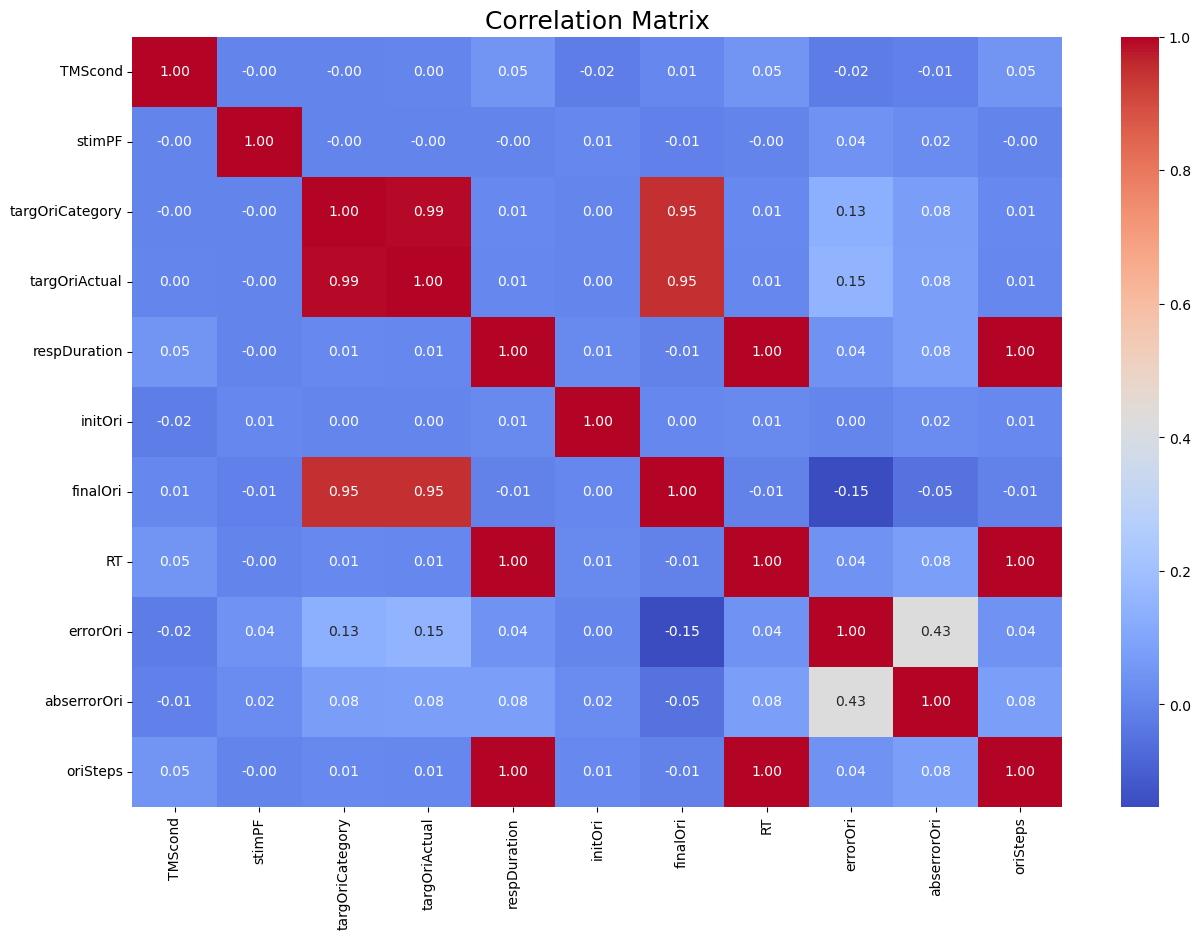

In [5]:
exploratory_cols = ['TMScond', 'stimPF', 'targOriCategory', 'targOriActual', 'respDuration', 'initOri', 'finalOri', 'RT', 'errorOri', 'abserrorOri', 'oriSteps']
plt.figure(figsize=(15, 10))
sns.heatmap(df[exploratory_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix', fontsize=title_fontsize)
plt.show()

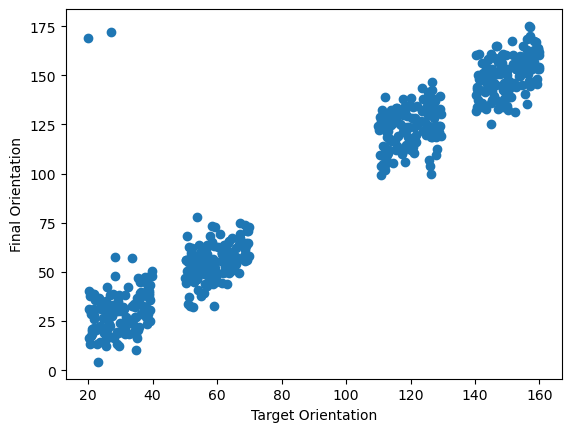

In [6]:
df_temp = df[df['subjID']==7].copy()
plt.figure()
plt.plot(df_temp['targOriActual'], df_temp['finalOri'], 'o')
plt.xlabel('Target Orientation')
plt.ylabel('Final Orientation')
plt.show()

<Figure size 1500x1000 with 0 Axes>

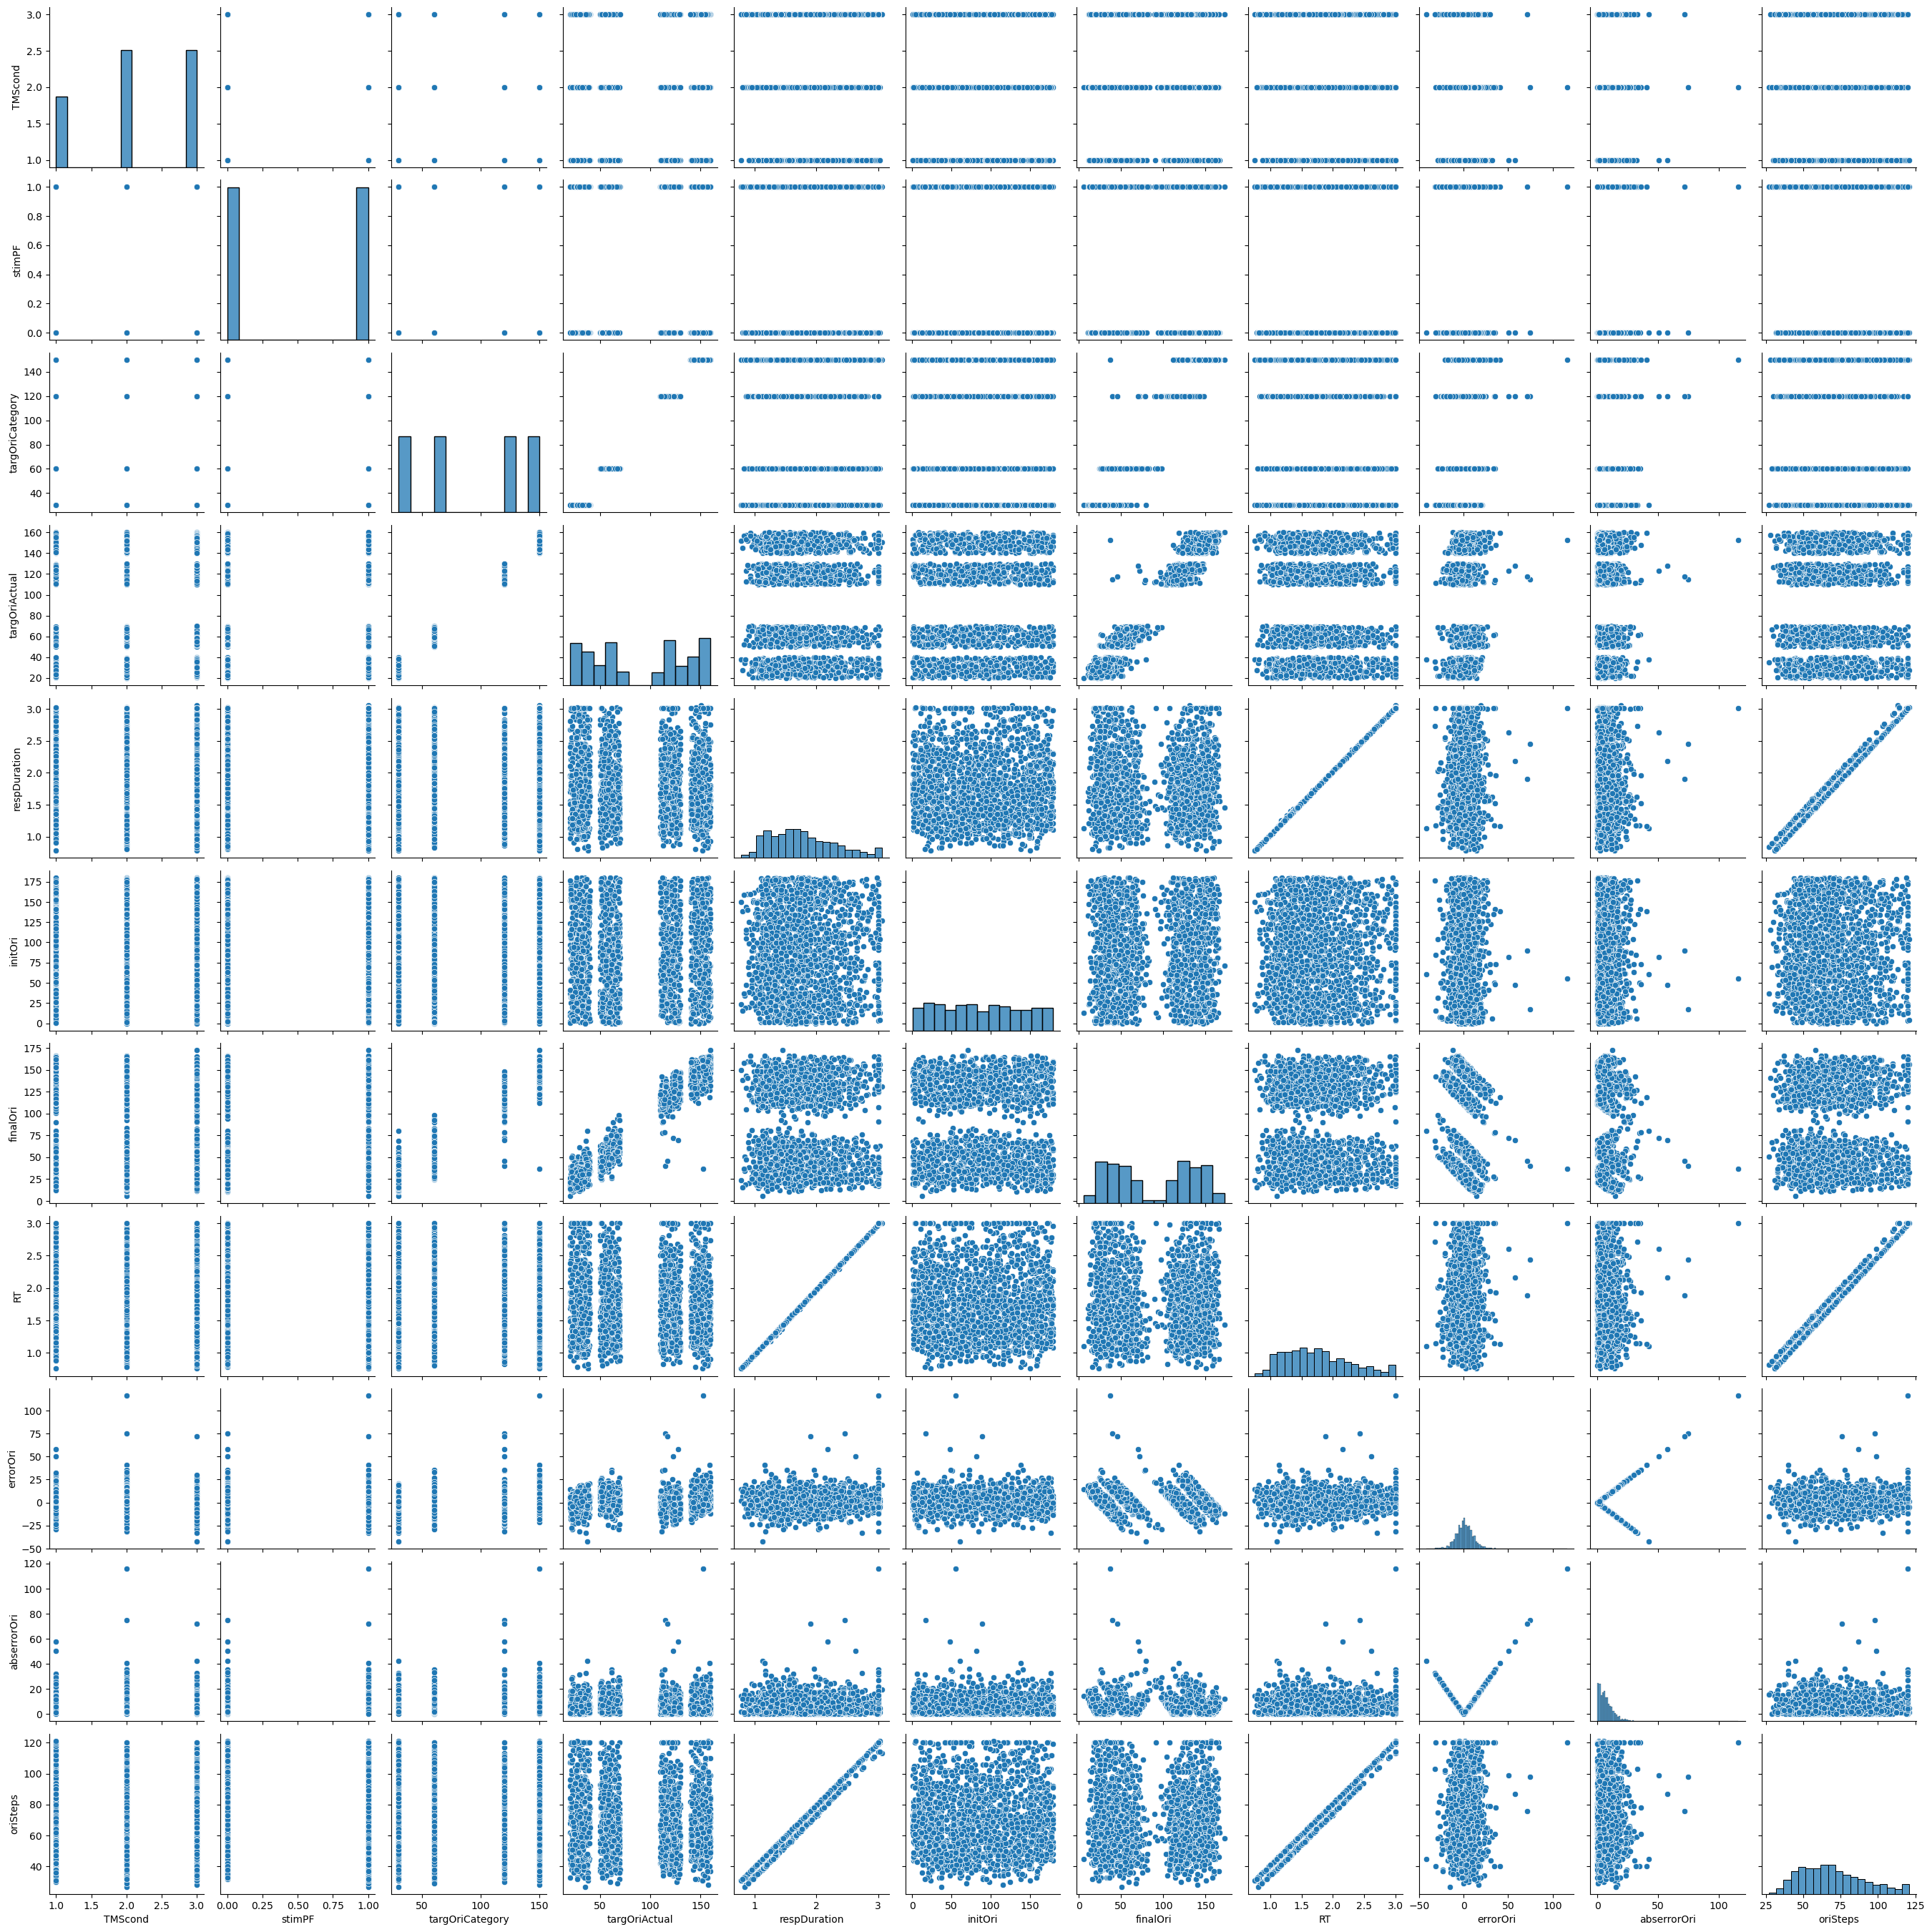

In [8]:
plt.figure(figsize=(15, 10))
sns.pairplot(df[exploratory_cols])
plt.show()

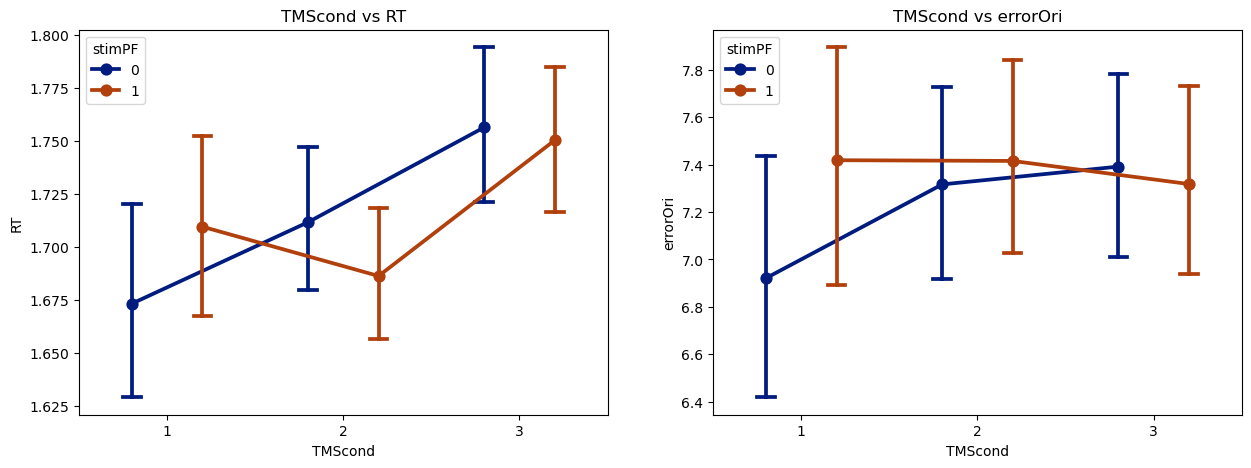

In [8]:
f, axs = plt.subplots(1, 2, figsize=(15, 5))
# sns.violinplot(x='TMScond', y='RT', data=df, ax=axs[0], hue='stimPF', dodge=True, inner=None)
df_temp = df.copy()
# For each subject, eliminate trials where abserrorOri is greater than 3 std devs from the mean
df_temp_modif = pd.DataFrame()
for sub in df_temp['subjID'].unique():
    subdf = df_temp[df_temp['subjID'] == sub]
    elimTrials = np.abs(subdf['abserrorOri'] - subdf['abserrorOri'].mean()) > 3*subdf['abserrorOri'].std()
    subdf = subdf[~elimTrials]
    df_temp_modif = pd.concat([df_temp_modif, subdf])
    # df_temp = df_temp[~elimTrials]
sns.pointplot(x='TMScond', y='RT', data=df_temp_modif, ax=axs[0], hue='stimPF', dodge=0.4, markers='o', capsize=.1, palette='dark')

axs[0].set_title('TMScond vs RT')
axs[0].set_xlabel('TMScond')
axs[0].set_ylabel('RT')

# sns.violinplot(x='TMScond', y='errorOri', data=df, ax=axs[1], hue='stimPF', dodge=True, inner=None)
sns.pointplot(x='TMScond', y='abserrorOri', data=df_temp_modif, ax=axs[1], hue='stimPF', dodge=0.4, markers='o', capsize=.1, palette='dark')
axs[1].set_title('TMScond vs errorOri')
axs[1].set_xlabel('TMScond')
axs[1].set_ylabel('errorOri')
plt.show()



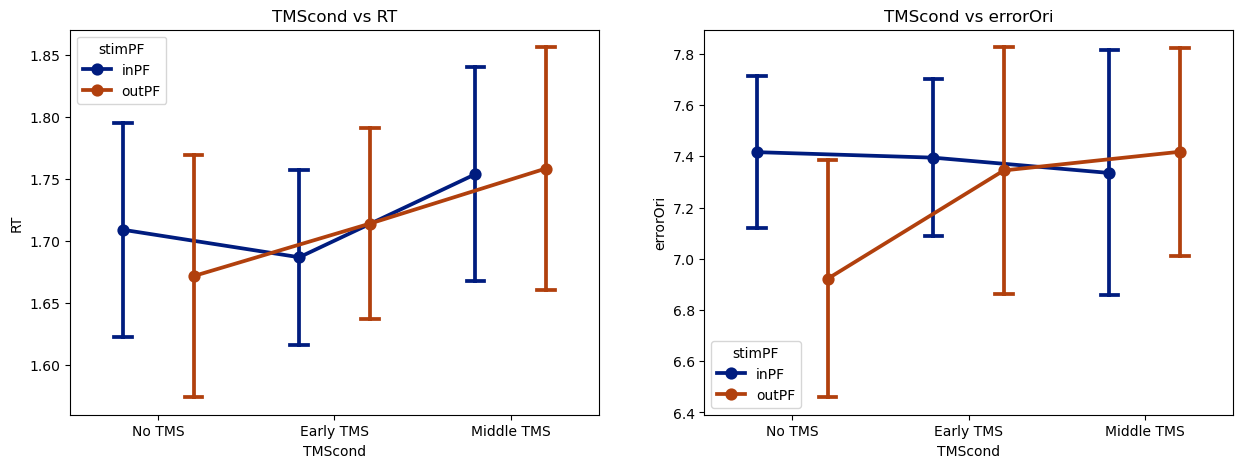

In [9]:
grouped_df = df_temp_modif.groupby(['subjID', 'TMScond_label', 'stimPF_label']).agg({
    'RT': ['mean', 'sem'],
    'abserrorOri': ['mean', 'sem']
}).reset_index()

grouped_df.columns = ['subjID', 'TMScond', 'stimPF', 'RT_mean', 'RT_sem', 'abserrorOri_mean', 'abserrorOri_sem']

f, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.pointplot(x='TMScond', y='RT_mean', data=grouped_df, ax=axs[0], hue='stimPF', dodge=0.4, 
              markers='o', capsize=.1, palette='dark', errorbar='se', order=['No TMS', 'Early TMS', 'Middle TMS'])

axs[0].set_title('TMScond vs RT')
axs[0].set_xlabel('TMScond')
axs[0].set_ylabel('RT')

sns.pointplot(x='TMScond', y='abserrorOri_mean', data=grouped_df, ax=axs[1], hue='stimPF', dodge=0.4, 
              markers='o', capsize=.1, palette='dark', errorbar='se', order=['No TMS', 'Early TMS', 'Middle TMS'])

axs[1].set_title('TMScond vs errorOri')
axs[1].set_xlabel('TMScond')
axs[1].set_ylabel('errorOri')

plt.show()

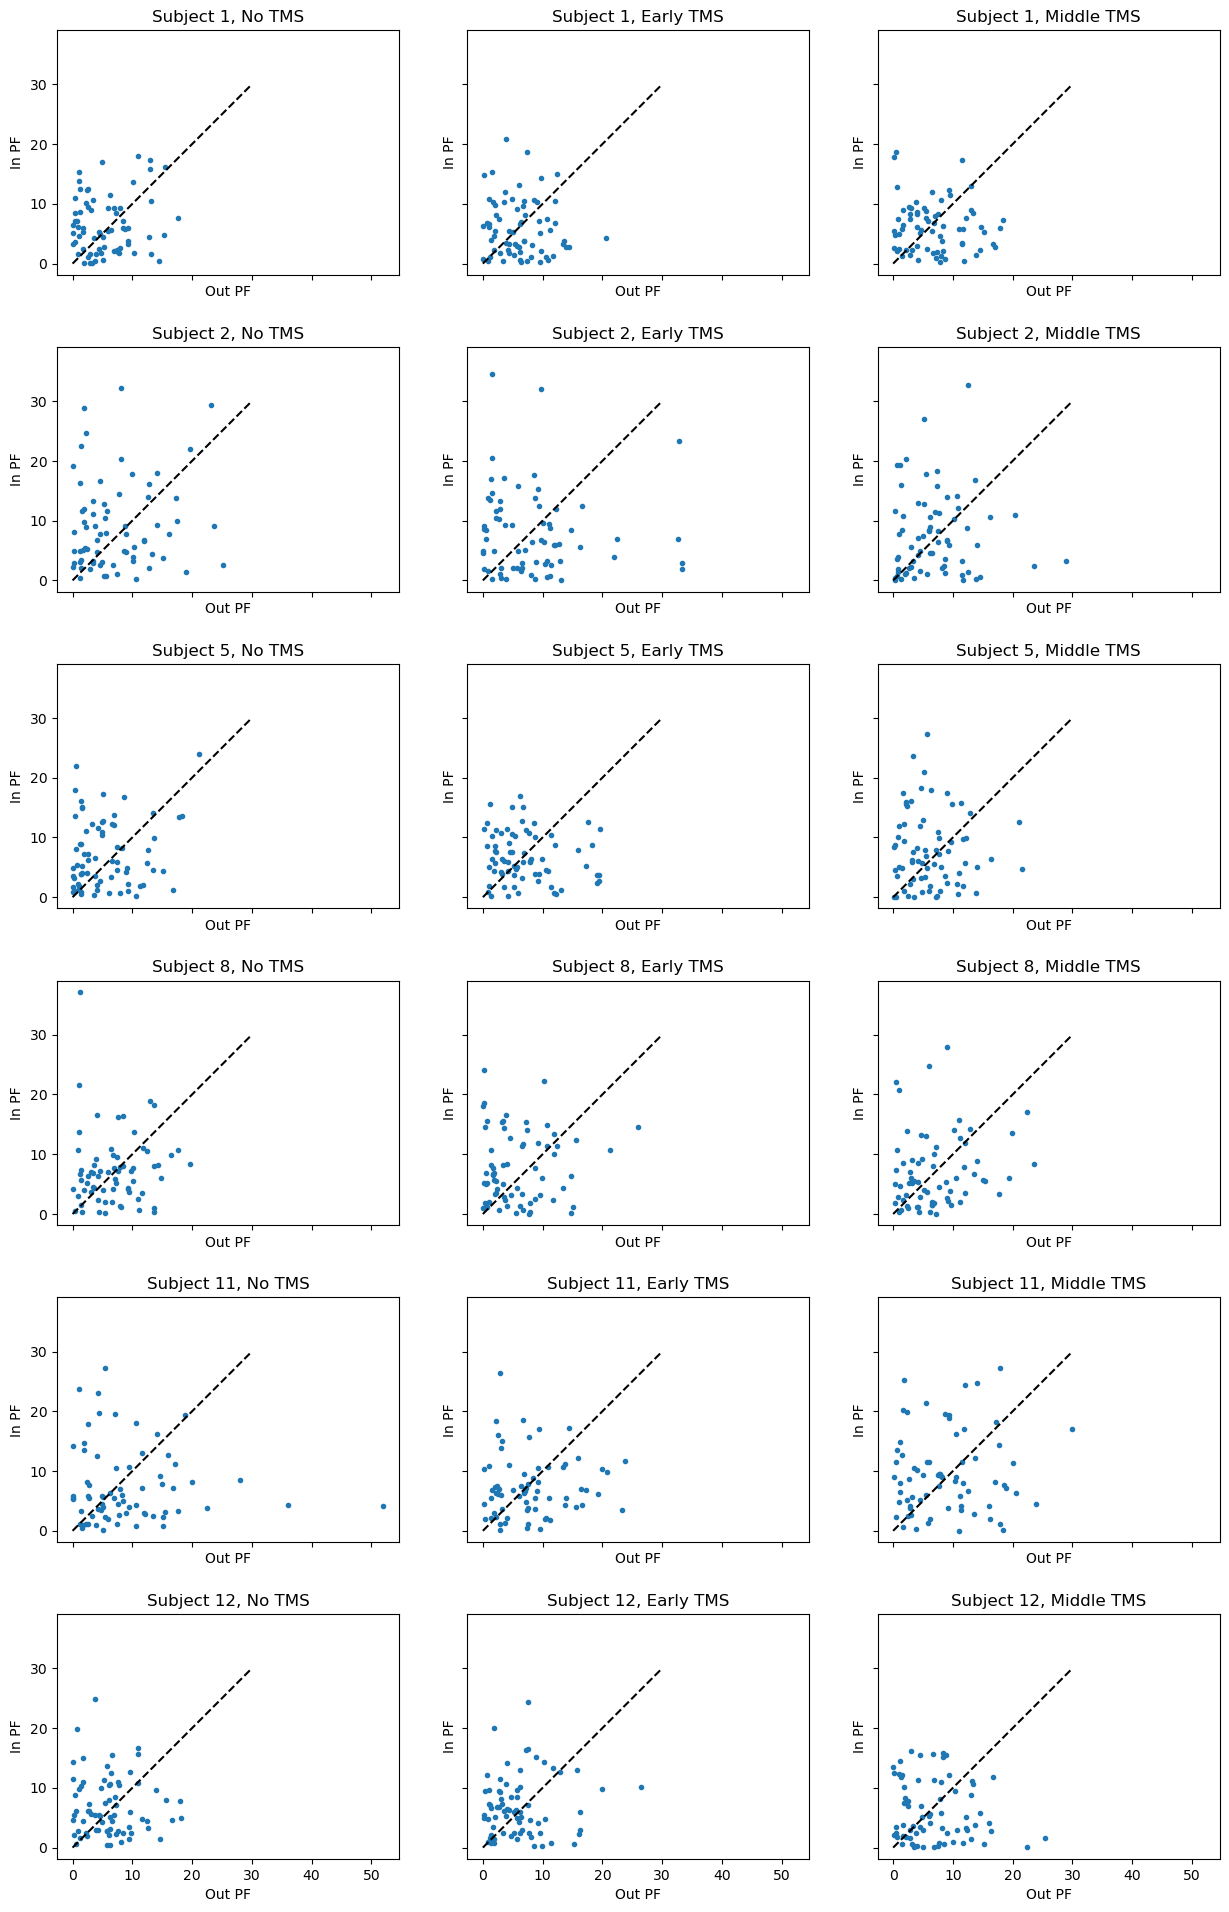

In [10]:
f, axs = plt.subplots(df['subjID'].nunique(), 3, figsize=(15, 4*df['subjID'].nunique()), sharex=True, sharey=True)
meetric_to_plot = 'abserrorOri'
for idx, sub in enumerate(df['subjID'].unique()):
    subdf = df[df['subjID'] == sub]
    elimTrials = np.abs(subdf['abserrorOri'] - subdf['abserrorOri'].mean()) > 3*subdf['abserrorOri'].std()
    subdf = subdf[~elimTrials]
    # Find the number of trials for each TMS condition and stimulus position
    ntrls_noTMS_outPF = subdf[(subdf['TMScond']==1) & (subdf['stimPF']==0)].shape[0]
    ntrls_noTMS_inPF = subdf[(subdf['TMScond']==1) & (subdf['stimPF']==1)].shape[0]
    ntrls_earlyTMS_outPF = subdf[(subdf['TMScond']==2) & (subdf['stimPF']==0)].shape[0]
    ntrls_earlyTMS_inPF = subdf[(subdf['TMScond']==2) & (subdf['stimPF']==1)].shape[0]
    ntrls_middleTMS_outPF = subdf[(subdf['TMScond']==3) & (subdf['stimPF']==0)].shape[0]
    ntrls_middleTMS_inPF = subdf[(subdf['TMScond']==3) & (subdf['stimPF']==1)].shape[0]

    ntrls_min = min(ntrls_noTMS_outPF, ntrls_noTMS_inPF, ntrls_earlyTMS_outPF, ntrls_earlyTMS_inPF, ntrls_middleTMS_outPF, ntrls_middleTMS_inPF)
    subdf = subdf.groupby(['TMScond', 'stimPF']).apply(lambda x: x.sample(n=ntrls_min)).reset_index(drop=True)

    axs[idx, 0].plot(subdf[(subdf['TMScond']==1) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==1) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 0].plot([0, 30], [0, 30], 'k--')
    axs[idx, 0].set_title(f'Subject {sub}, No TMS')
    axs[idx, 0].set_xlabel('Out PF')
    axs[idx, 0].set_ylabel('In PF')
    axs[idx, 0].set_aspect('equal')

    axs[idx, 1].plot(subdf[(subdf['TMScond']==2) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==2) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 1].plot([0, 30], [0, 30], 'k--')
    axs[idx, 1].set_title(f'Subject {sub}, Early TMS')
    axs[idx, 1].set_xlabel('Out PF')
    axs[idx, 1].set_ylabel('In PF')
    axs[idx, 1].set_aspect('equal')

    axs[idx, 2].plot(subdf[(subdf['TMScond']==3) & (subdf['stimPF']==0)][metric_to_plot], subdf[(subdf['TMScond']==3) & (subdf['stimPF']==1)][metric_to_plot], 'o', markersize=msize*0.3)
    axs[idx, 2].plot([0, 30], [0, 30], 'k--')
    axs[idx, 2].set_title(f'Subject {sub}, Middle TMS')
    axs[idx, 2].set_xlabel('Out PF')
    axs[idx, 2].set_ylabel('In PF')
    axs[idx, 2].set_aspect('equal')
plt.show()
    

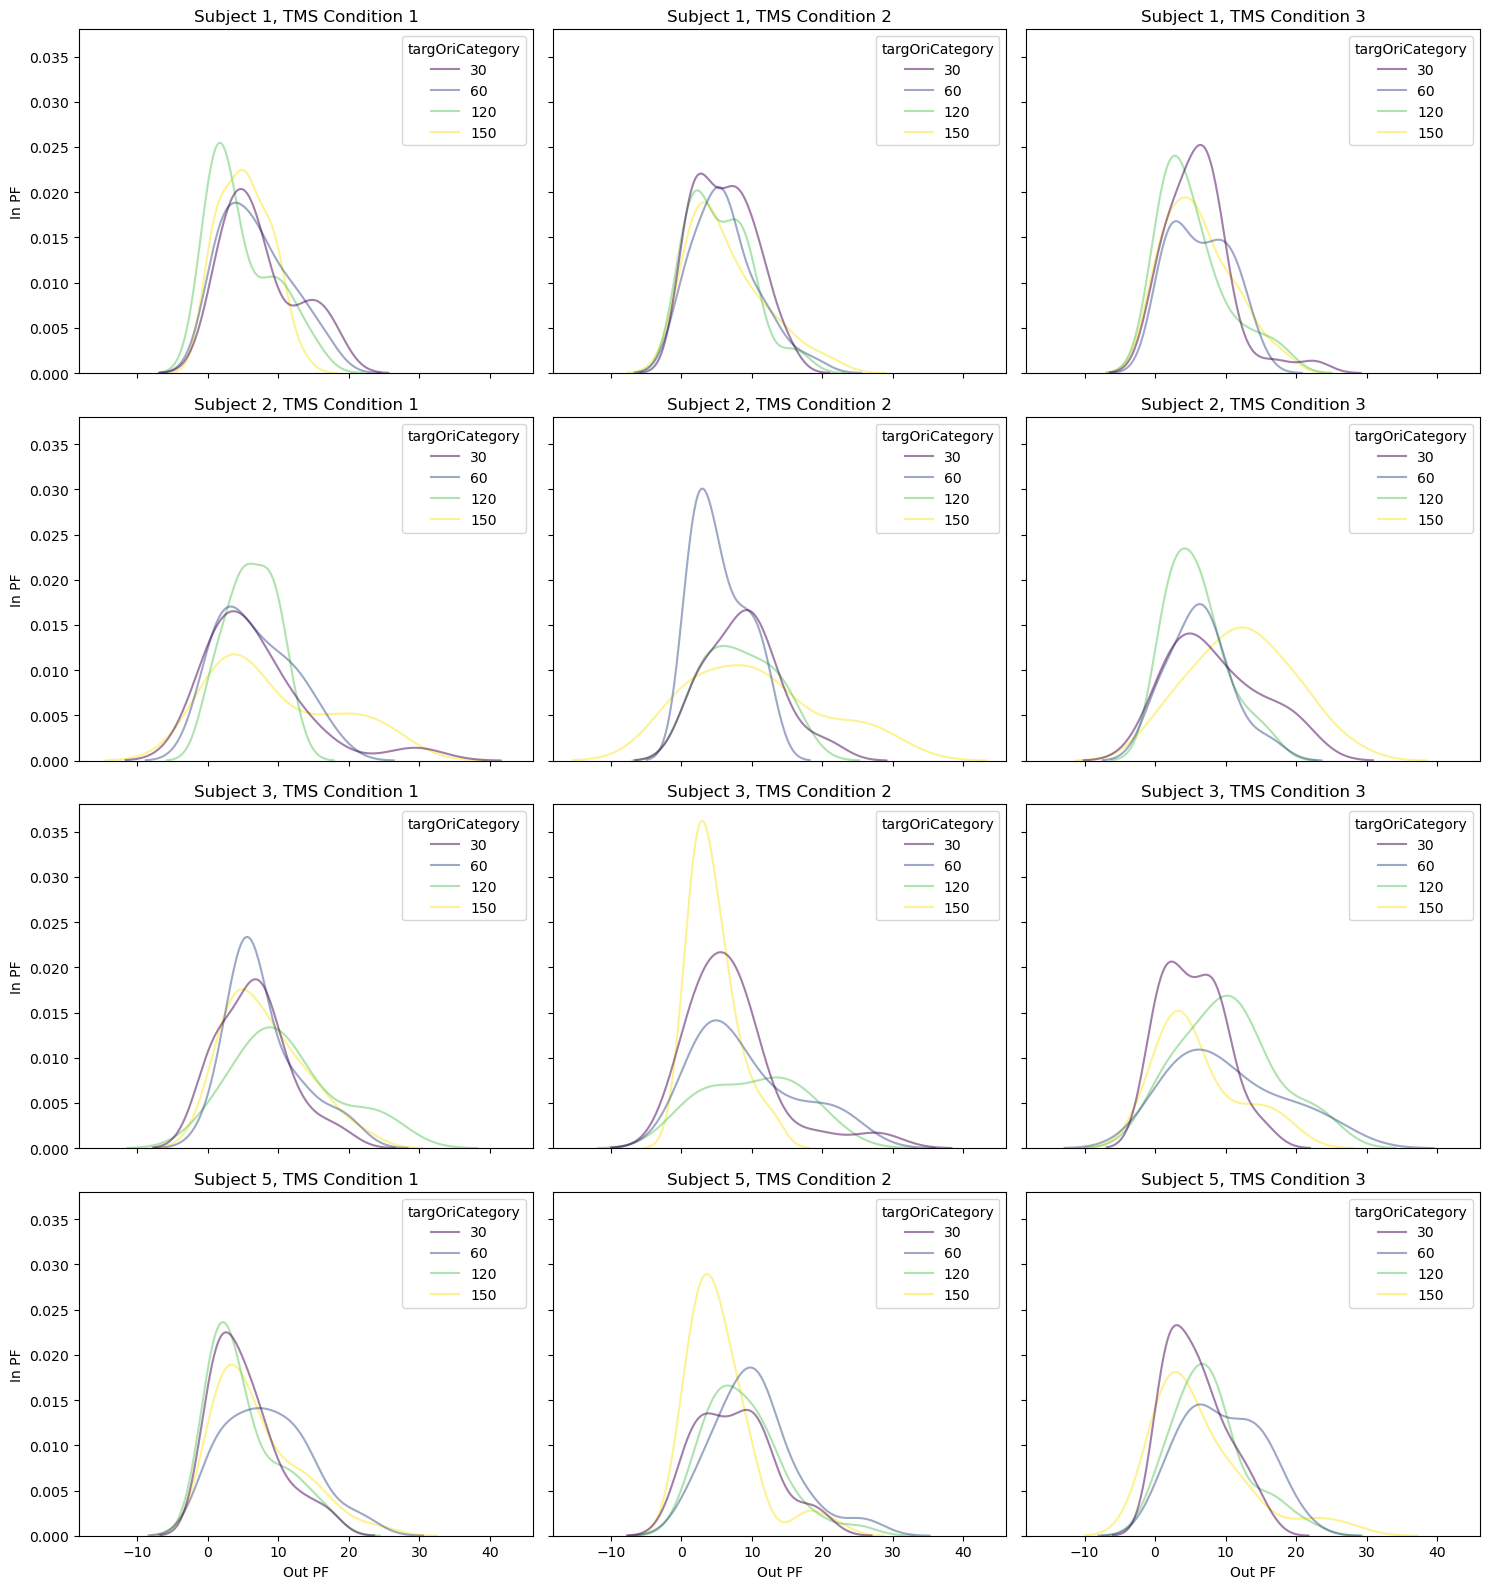

In [123]:
f, axs = plt.subplots(df['subjID'].nunique(), 3, figsize=(15, 4*df['subjID'].nunique()), sharex=True, sharey=True)
metric_to_plot = 'abserrorOri'

for idx, sub in enumerate(df['subjID'].unique()):
    subdf = df[df['subjID'] == sub]
    elimTrials = np.abs(subdf[metric_to_plot] - subdf[metric_to_plot].mean()) > 3*subdf[metric_to_plot].std()
    subdf = subdf[~elimTrials]
    
    # Balance the number of trials
    ntrls_noTMS_outPF = subdf[(subdf['TMScond']==1) & (subdf['stimPF']==0)].shape[0]
    ntrls_noTMS_inPF = subdf[(subdf['TMScond']==1) & (subdf['stimPF']==1)].shape[0]
    ntrls_earlyTMS_outPF = subdf[(subdf['TMScond']==2) & (subdf['stimPF']==0)].shape[0]
    ntrls_earlyTMS_inPF = subdf[(subdf['TMScond']==2) & (subdf['stimPF']==1)].shape[0]
    ntrls_middleTMS_outPF = subdf[(subdf['TMScond']==3) & (subdf['stimPF']==0)].shape[0]
    ntrls_middleTMS_inPF = subdf[(subdf['TMScond']==3) & (subdf['stimPF']==1)].shape[0]

    ntrls_min = min(ntrls_noTMS_outPF, ntrls_noTMS_inPF, ntrls_earlyTMS_outPF, ntrls_earlyTMS_inPF, ntrls_middleTMS_outPF, ntrls_middleTMS_inPF)
    subdf = subdf.groupby(['TMScond', 'stimPF']).apply(lambda x: x.sample(n=ntrls_min)).reset_index(drop=True)
    
    # Contour plot for each TMS condition
    for col, tms_cond in enumerate([1, 2, 3]):
        x_data = subdf[(subdf['TMScond']==tms_cond) & (subdf['stimPF']==0)][metric_to_plot]
        y_data = subdf[(subdf['TMScond']==tms_cond) & (subdf['stimPF']==1)][metric_to_plot]
        # print(x_data.var(), y_data.var())
        # print covariances
        # print(np.cov(x_data, y_data))
        # sns.kdeplot(x=x_data, y=y_data, ax=axs[idx, col])#, fill=True, cmap="viridis")
        # sns.kdeplot(data=subdf[(subdf['TMScond']==tms_cond)], x=metric_to_plot, y='RT', ax=axs[idx, col], fill=True)#, cmap='viridis', levels=5)
        sns.kdeplot(data=subdf[(subdf['TMScond']==tms_cond)], x=metric_to_plot, hue='targOriCategory', ax=axs[idx, col], fill=False, palette='viridis', alpha=0.5)
        # axs[idx, col].plot([0, 30], [0, 30], 'k--')
        axs[idx, col].set_title(f'Subject {sub}, TMS Condition {tms_cond}')
        axs[idx, col].set_xlabel('Out PF')
        axs[idx, col].set_ylabel('In PF')
        # axs[idx, col].set_aspect('equal')

plt.tight_layout()
plt.show()


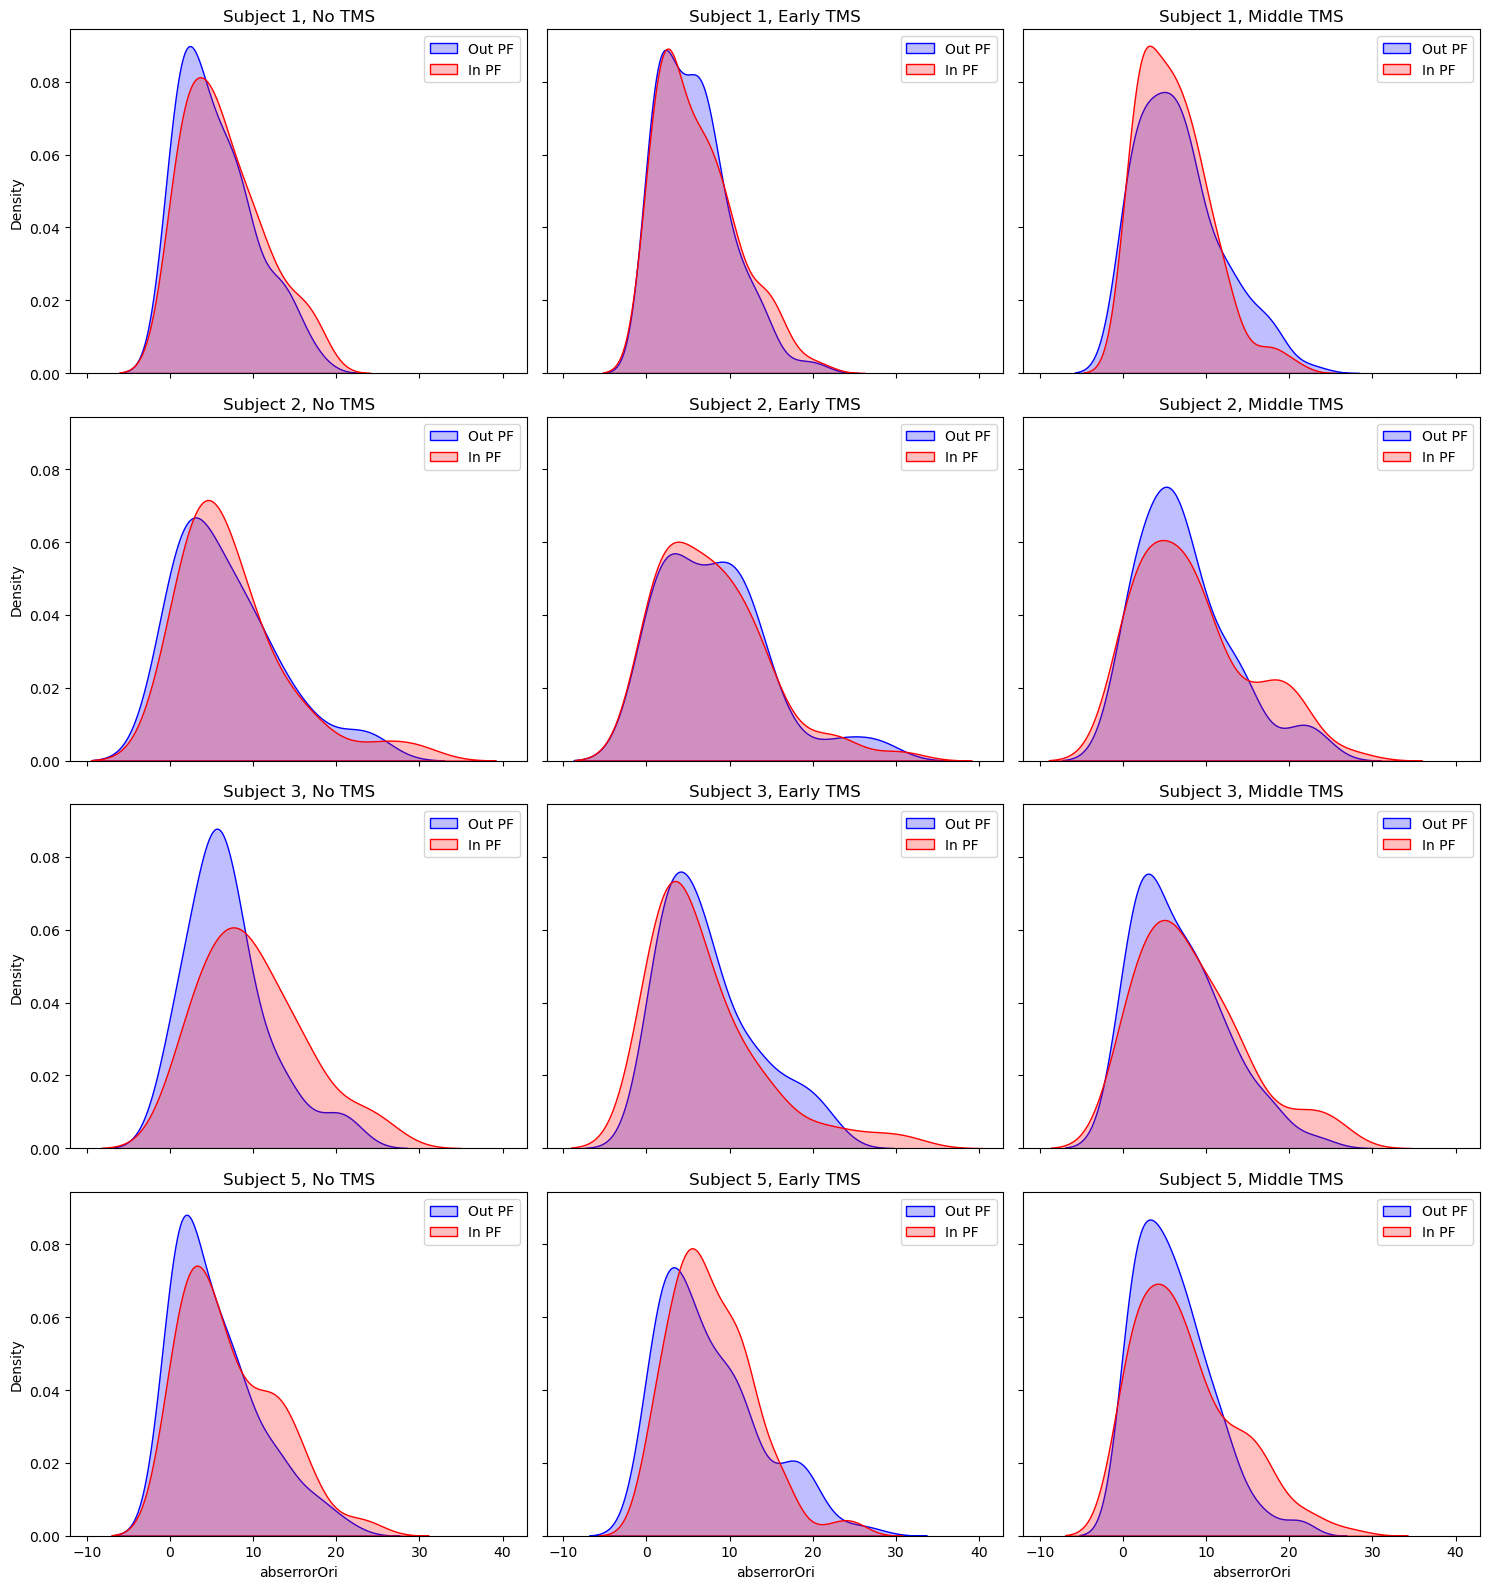

In [99]:
f, axs = plt.subplots(df['subjID'].nunique(), 3, figsize=(15, 4*df['subjID'].nunique()), sharex=True, sharey=True)
metric_to_plot = 'abserrorOri'

for idx, sub in enumerate(df['subjID'].unique()):
    subdf = df[df['subjID'] == sub]
    elimTrials = np.abs(subdf[metric_to_plot] - subdf[metric_to_plot].mean()) > 3 * subdf[metric_to_plot].std()
    subdf = subdf[~elimTrials]

    # Balance the number of trials across conditions
    ntrls_noTMS_outPF = subdf[(subdf['TMScond'] == 1) & (subdf['stimPF'] == 0)].shape[0]
    ntrls_noTMS_inPF = subdf[(subdf['TMScond'] == 1) & (subdf['stimPF'] == 1)].shape[0]
    ntrls_earlyTMS_outPF = subdf[(subdf['TMScond'] == 2) & (subdf['stimPF'] == 0)].shape[0]
    ntrls_earlyTMS_inPF = subdf[(subdf['TMScond'] == 2) & (subdf['stimPF'] == 1)].shape[0]
    ntrls_middleTMS_outPF = subdf[(subdf['TMScond'] == 3) & (subdf['stimPF'] == 0)].shape[0]
    ntrls_middleTMS_inPF = subdf[(subdf['TMScond'] == 3) & (subdf['stimPF'] == 1)].shape[0]

    ntrls_min = min(ntrls_noTMS_outPF, ntrls_noTMS_inPF, ntrls_earlyTMS_outPF, ntrls_earlyTMS_inPF, ntrls_middleTMS_outPF, ntrls_middleTMS_inPF)
    # subdf = subdf.groupby(['TMScond', 'stimPF']).apply(lambda x: x.sample(n=ntrls_min)).reset_index(drop=True)

    # Plot distributions and their difference for each TMS condition
    for col, tms_cond in enumerate([1, 2, 3]):
        sns.kdeplot(subdf[(subdf['TMScond'] == tms_cond) & (subdf['stimPF'] == 0)][metric_to_plot], ax=axs[idx, col], label='Out PF', color='blue', fill=True)
        sns.kdeplot(subdf[(subdf['TMScond'] == tms_cond) & (subdf['stimPF'] == 1)][metric_to_plot], ax=axs[idx, col], label='In PF', color='red', fill=True)
        # sns.histplot(subdf[(subdf['TMScond'] == tms_cond) & (subdf['stimPF'] == 0)][metric_to_plot], ax=axs[idx, col], label='Out PF', color='blue', kde=False, bins=50)
        # sns.histplot(subdf[(subdf['TMScond'] == tms_cond) & (subdf['stimPF'] == 1)][metric_to_plot], ax=axs[idx, col], label='In PF', color='red', kde=False, bins=50)

        # Calculate the difference between the distributions
        # diff = np.histogram(subdf[(subdf['TMScond'] == tms_cond) & (subdf['stimPF'] == 1)][metric_to_plot], bins=100, density=True)[0] - \
        #        np.histogram(subdf[(subdf['TMScond'] == tms_cond) & (subdf['stimPF'] == 0)][metric_to_plot], bins=100, density=True)[0]
        
        # # Optionally, overlay the difference
        # axs[idx, col].plot(diff, label='Difference', color='green')
        if tms_cond == 1:
            axs[idx, col].set_title(f'Subject {sub}, No TMS')
        elif tms_cond == 2:
            axs[idx, col].set_title(f'Subject {sub}, Early TMS')
        else:
            axs[idx, col].set_title(f'Subject {sub}, Middle TMS')
        axs[idx, col].legend()

plt.tight_layout()
plt.show()


In [11]:
PF_arr = [0, 1]
targOriCategory_arr = df['targOriCategory'].unique()
RT_holder = np.empty((len(PF_arr), len(targOriCategory_arr)))
error_holder = np.empty((len(PF_arr), len(targOriCategory_arr)))

from itertools import product
for ii, jj in product(range(len(PF_arr)), range(len(targOriCategory_arr))):
    RT_holder[ii, jj] = df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'] == targOriCategory_arr[jj])]['RT'].mean()
    error_holder[ii, jj] = df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'] == targOriCategory_arr[jj])]['abserrorOri'].mean()

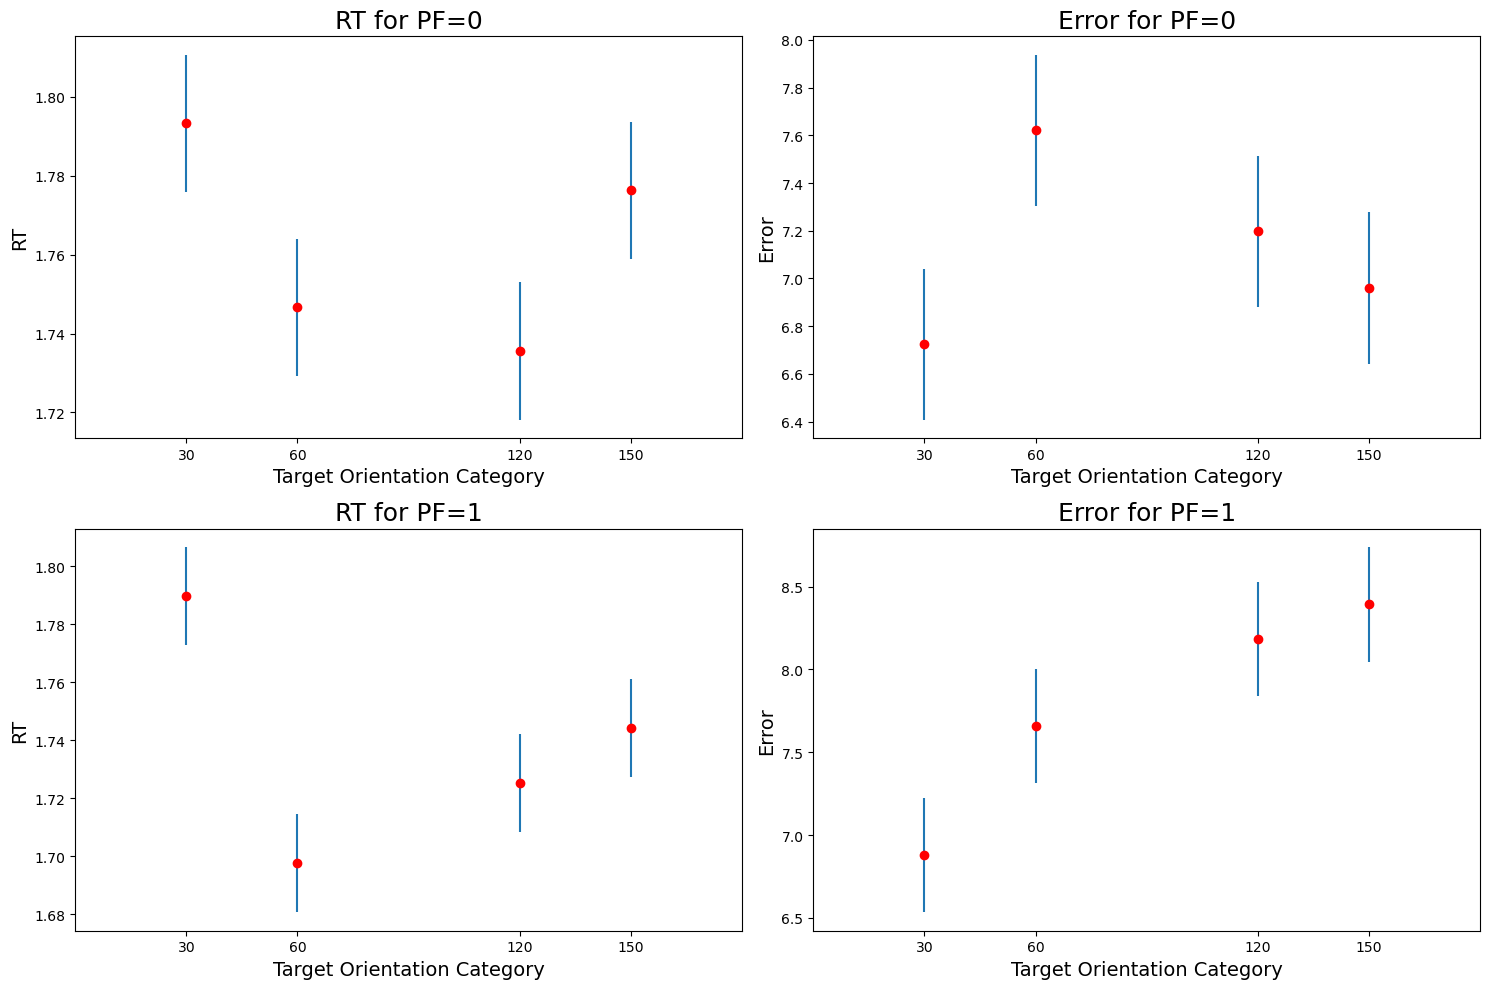

In [12]:
# Plot mean and error for both RT and error for different PF_arr
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
for ii in range(len(PF_arr)):
    # ax[ii, 0].bar(targOriCategory_arr, RT_holder[ii, :], label=f'PF={PF_arr[ii]}')
    # ax[ii, 1].bar(targOriCategory_arr, error_holder[ii, :], label=f'PF={PF_arr[ii]}')
    axs[ii, 0].errorbar(targOriCategory_arr, RT_holder[ii, :], yerr=stats.sem(df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'].isin(targOriCategory_arr))]['RT']), ls='None', label=f'PF={PF_arr[ii]}')
    axs[ii, 0].plot(targOriCategory_arr, RT_holder[ii, :], 'ro')
    axs[ii, 0].set_xlim(0, 180)
    axs[ii, 0].set_xticks(targOriCategory_arr)
    axs[ii, 0].set_title(f'RT for PF={PF_arr[ii]}', fontsize=title_fontsize)
    axs[ii, 0].set_xlabel('Target Orientation Category', fontsize=axes_fontsize)
    axs[ii, 0].set_ylabel('RT', fontsize=axes_fontsize)
    axs[ii, 1].errorbar(targOriCategory_arr, error_holder[ii, :], yerr=stats.sem(df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'].isin(targOriCategory_arr))]['errorOri']), ls='None', label=f'PF={PF_arr[ii]}')
    axs[ii, 1].plot(targOriCategory_arr, error_holder[ii, :], 'ro')
    axs[ii, 1].set_xlim(0, 180)
    axs[ii, 1].set_xticks(targOriCategory_arr)
    axs[ii, 1].set_title(f'Error for PF={PF_arr[ii]}', fontsize=title_fontsize)
    axs[ii, 1].set_xlabel('Target Orientation Category', fontsize=axes_fontsize)
    axs[ii, 1].set_ylabel('Error', fontsize=axes_fontsize)
plt.tight_layout()
plt.show()